In [7]:
import sys
sys.path.append("./../") 

import numpy as np
import torch
import seaborn as sns

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FormatStrFormatter

from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader

from scripts.utils import load_array, load_model
from scripts.evaluation.data_utils import numpy_to_dataset
from scripts.models.utils import eval_model
from scripts.cshap.decomposition.custom_decomposition import CustomDecomposition

This notebook contains a more expansive analysis of the C-SHAP explanations when calculating C-SHAP using the custom decomposition on the OPPORTUNITY dataset.

<h2> Initialization </h2>
Start with initialization and loading the data, model and SHAP values.

In [8]:
# Colours used for visualization
colors = ["#A338C4", '#248EF1', "#29BA10", '#F68D0E', '#F12476']

In [9]:
# Initialize settings
dataset = 'opportunity_uni'     # Dataset name
class_dict = {0:'Stand', 1:'Walk', 2:'Sit', 3:'Lie'}                    # Mapping between labels and targets for the dataset
decomposition_def = 'trend+bias+scale*(low_freq+var*high_freq)'         # Definition for custom decomposition  
task = 'classification'                                                 # Task should be classification or regression
bidirectional = True                                                    # Whether pred. GRU model should use bidirectional layers
input_dim = 1                                                           # Number of input variables (1 since univariate data)

In [10]:
# Used for model evaluation
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu") # Device to load model onto
batch_size = 32                                                         # Batch size used for model evaluation

In [11]:
data_path = './../data/prepared/' + dataset + '/'
shap_path = './../data/cshap/' + dataset + '/uni_channel/' + decomposition_def
shap_path = shap_path.replace('*', 'x')
model_path = './../models/' + dataset + '/uni_channel'
model_name = 'model_0.pt'

In [12]:
# Load prepared data
# Signals
X_train = load_array(data_path + '/X_train.pkl')
X_test = load_array(data_path +  '/X_test.pkl')

# Targets
y_train = load_array(data_path +  '/y_train.pkl')
y_test = load_array(data_path +  '/y_test.pkl')

# Ensure proper shape
if len(X_train.shape) == 2:
    X_train = X_train[:, :, None]
    X_test = X_test[:, :, None]

# Load C-SHAP values
shap_values = load_array(shap_path + '/shap_values0.pkl')

In [13]:
# Load model from file
model = load_model(model_path, task, bidirectional, X_train.shape[-1], class_dict, device, model_name=model_name)

<h2> Confusion matrix </h2>

In [14]:
# Get test predictions for confusion matrix
test_dataset = numpy_to_dataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size)
test_acc, test_preds, test_gts = eval_model(task, model, test_loader, device, class_dict)

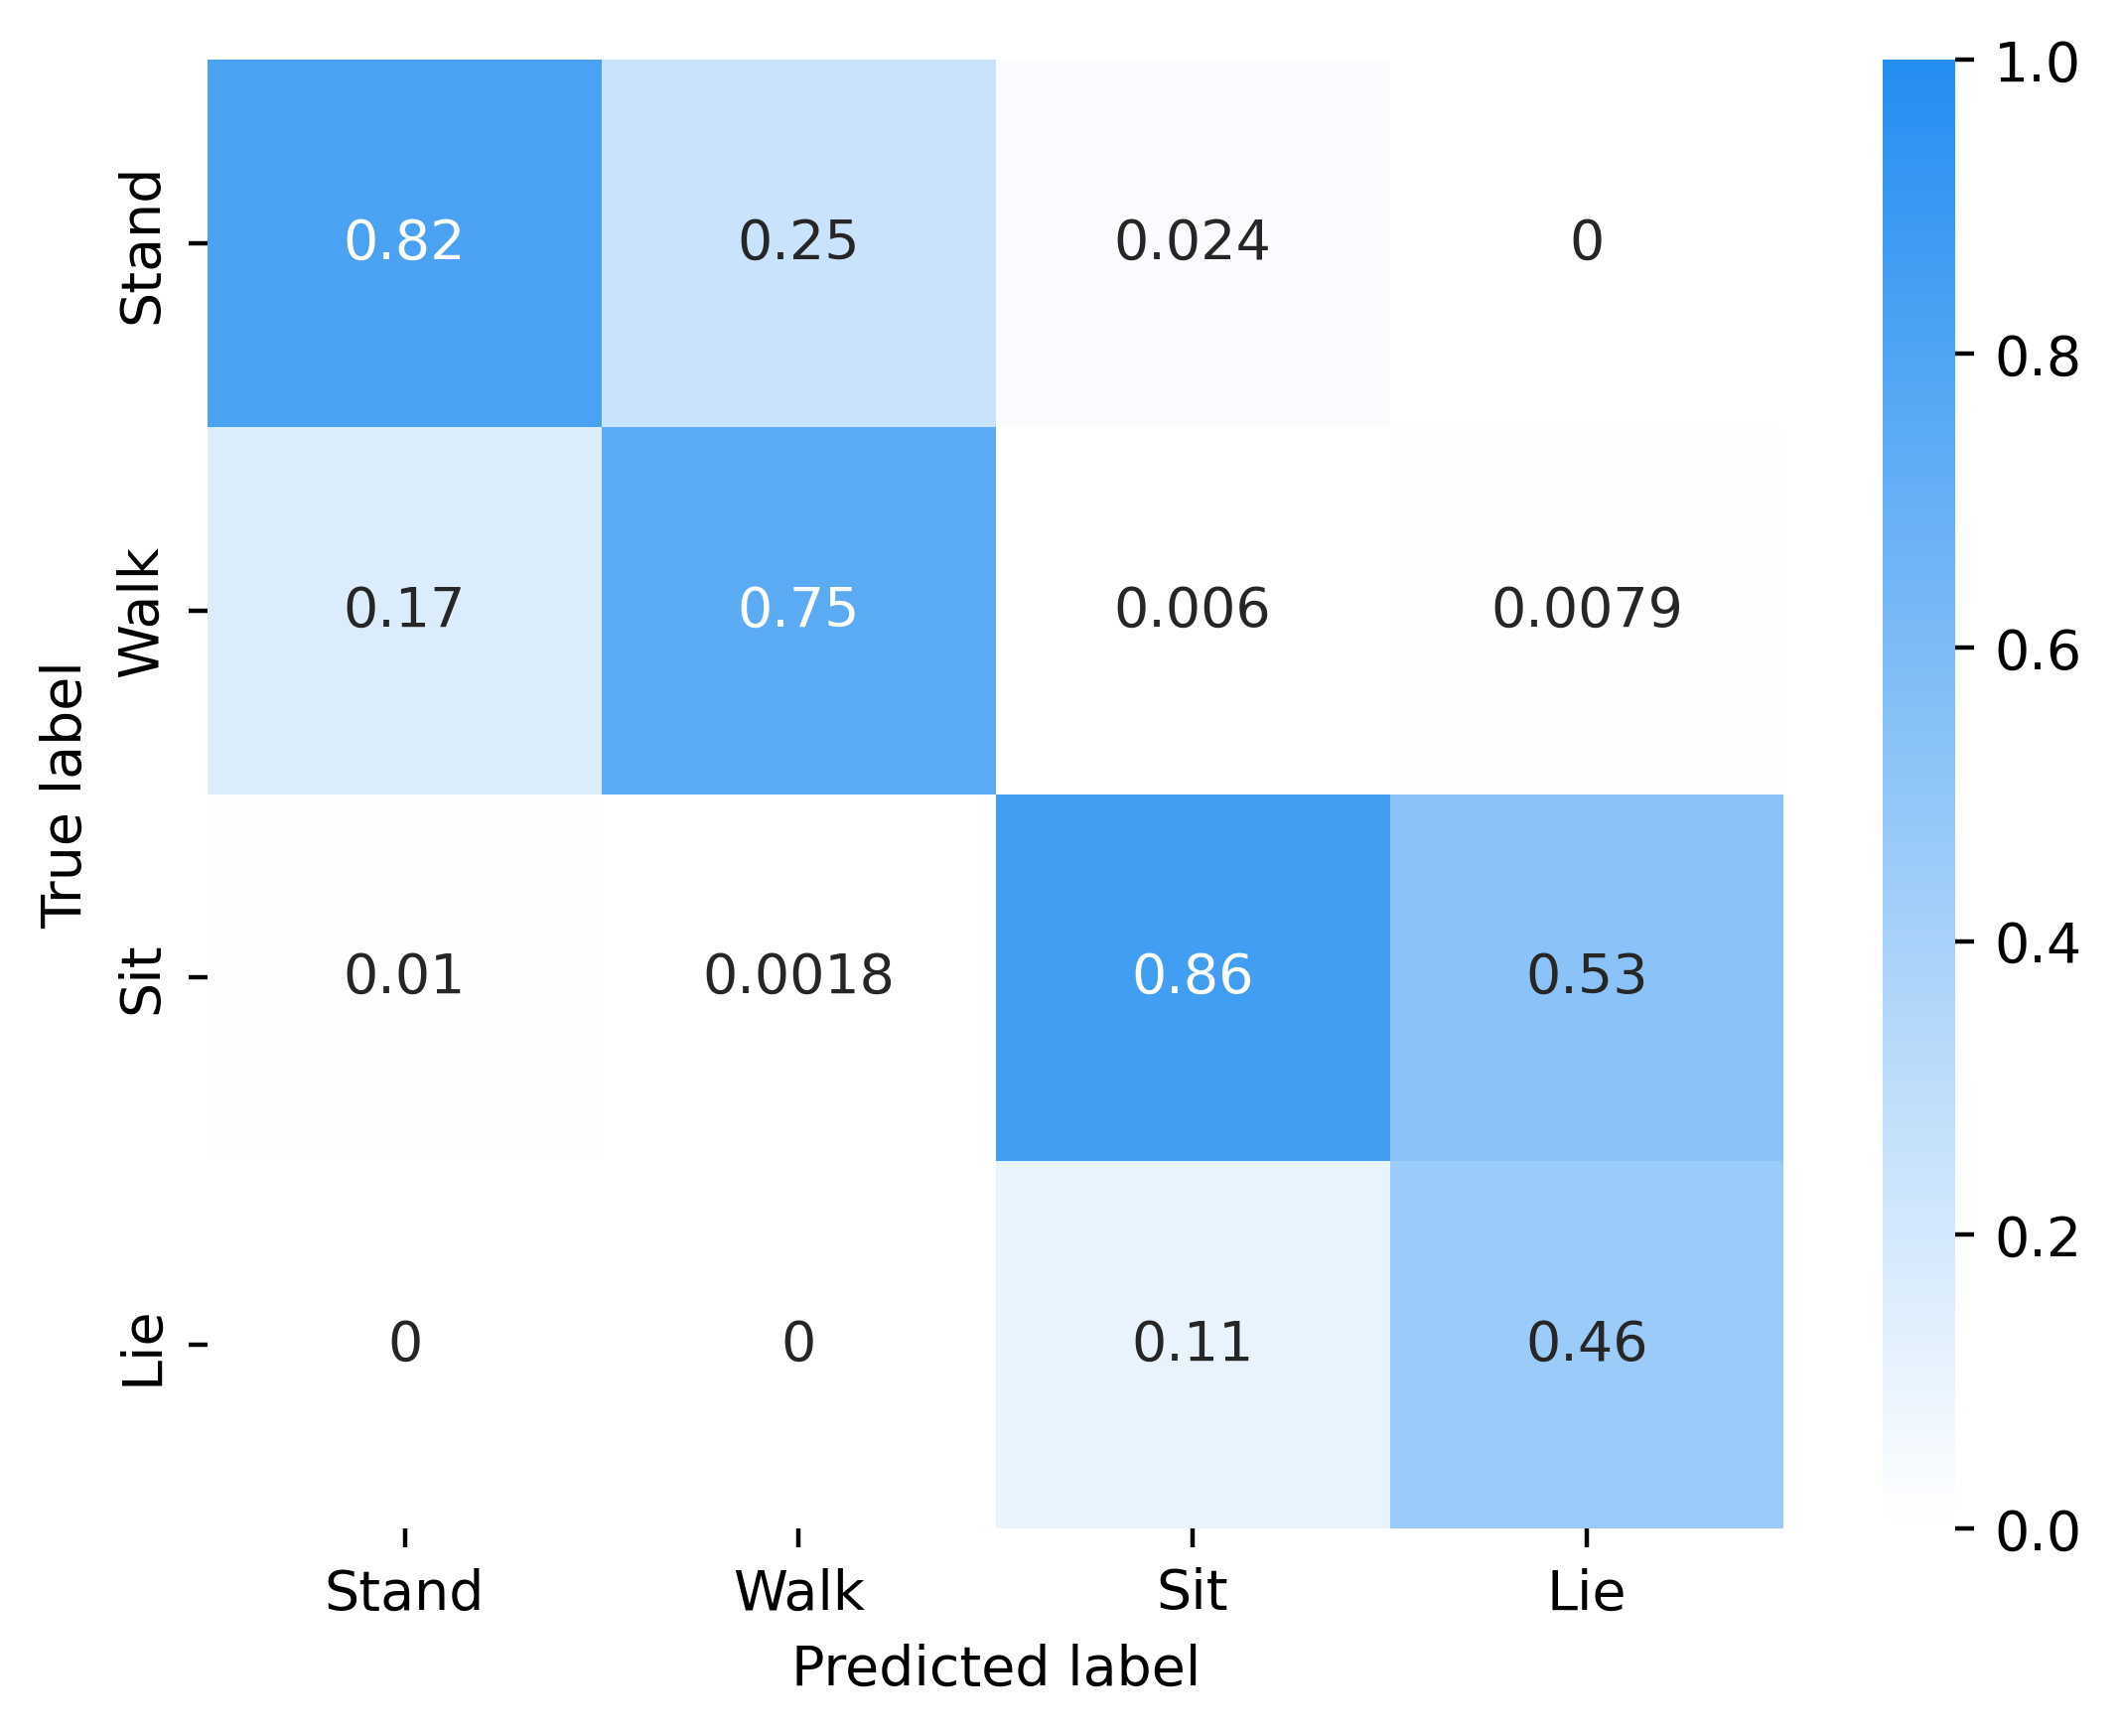

In [15]:
# Set custom colormap
cmap = LinearSegmentedColormap.from_list('custom_cmap', ['#FFFFFF', colors[1]])

# Initialize figure for confusion matrix
plt.figure(dpi=400)
cm = confusion_matrix(test_gts, test_preds, normalize='pred')
sns.heatmap(cm, vmin=0, vmax=1, annot=True,cmap=cmap)
plt.xticks(list(np.arange(0.5, 4.5, 1)), list(class_dict.values()))     # Set class names as ticks
plt.yticks(list(np.arange(0.5, 4.5, 1)), list(class_dict.values()))
plt.ylabel('True label')
plt.xlabel('Predicted label');

<h2> Component values </h2> 

In [16]:
# Initialize decomposition
var_window_size = 27
noise_sigma = 1
decomposition = CustomDecomposition(decomposition_def, noise_sigma=noise_sigma, var_window_size=var_window_size)
t = np.linspace(0, X_test.shape[1], X_test.shape[1])

In [17]:
# Decompose test data
x_components = decomposition.decompose(t, X_test)

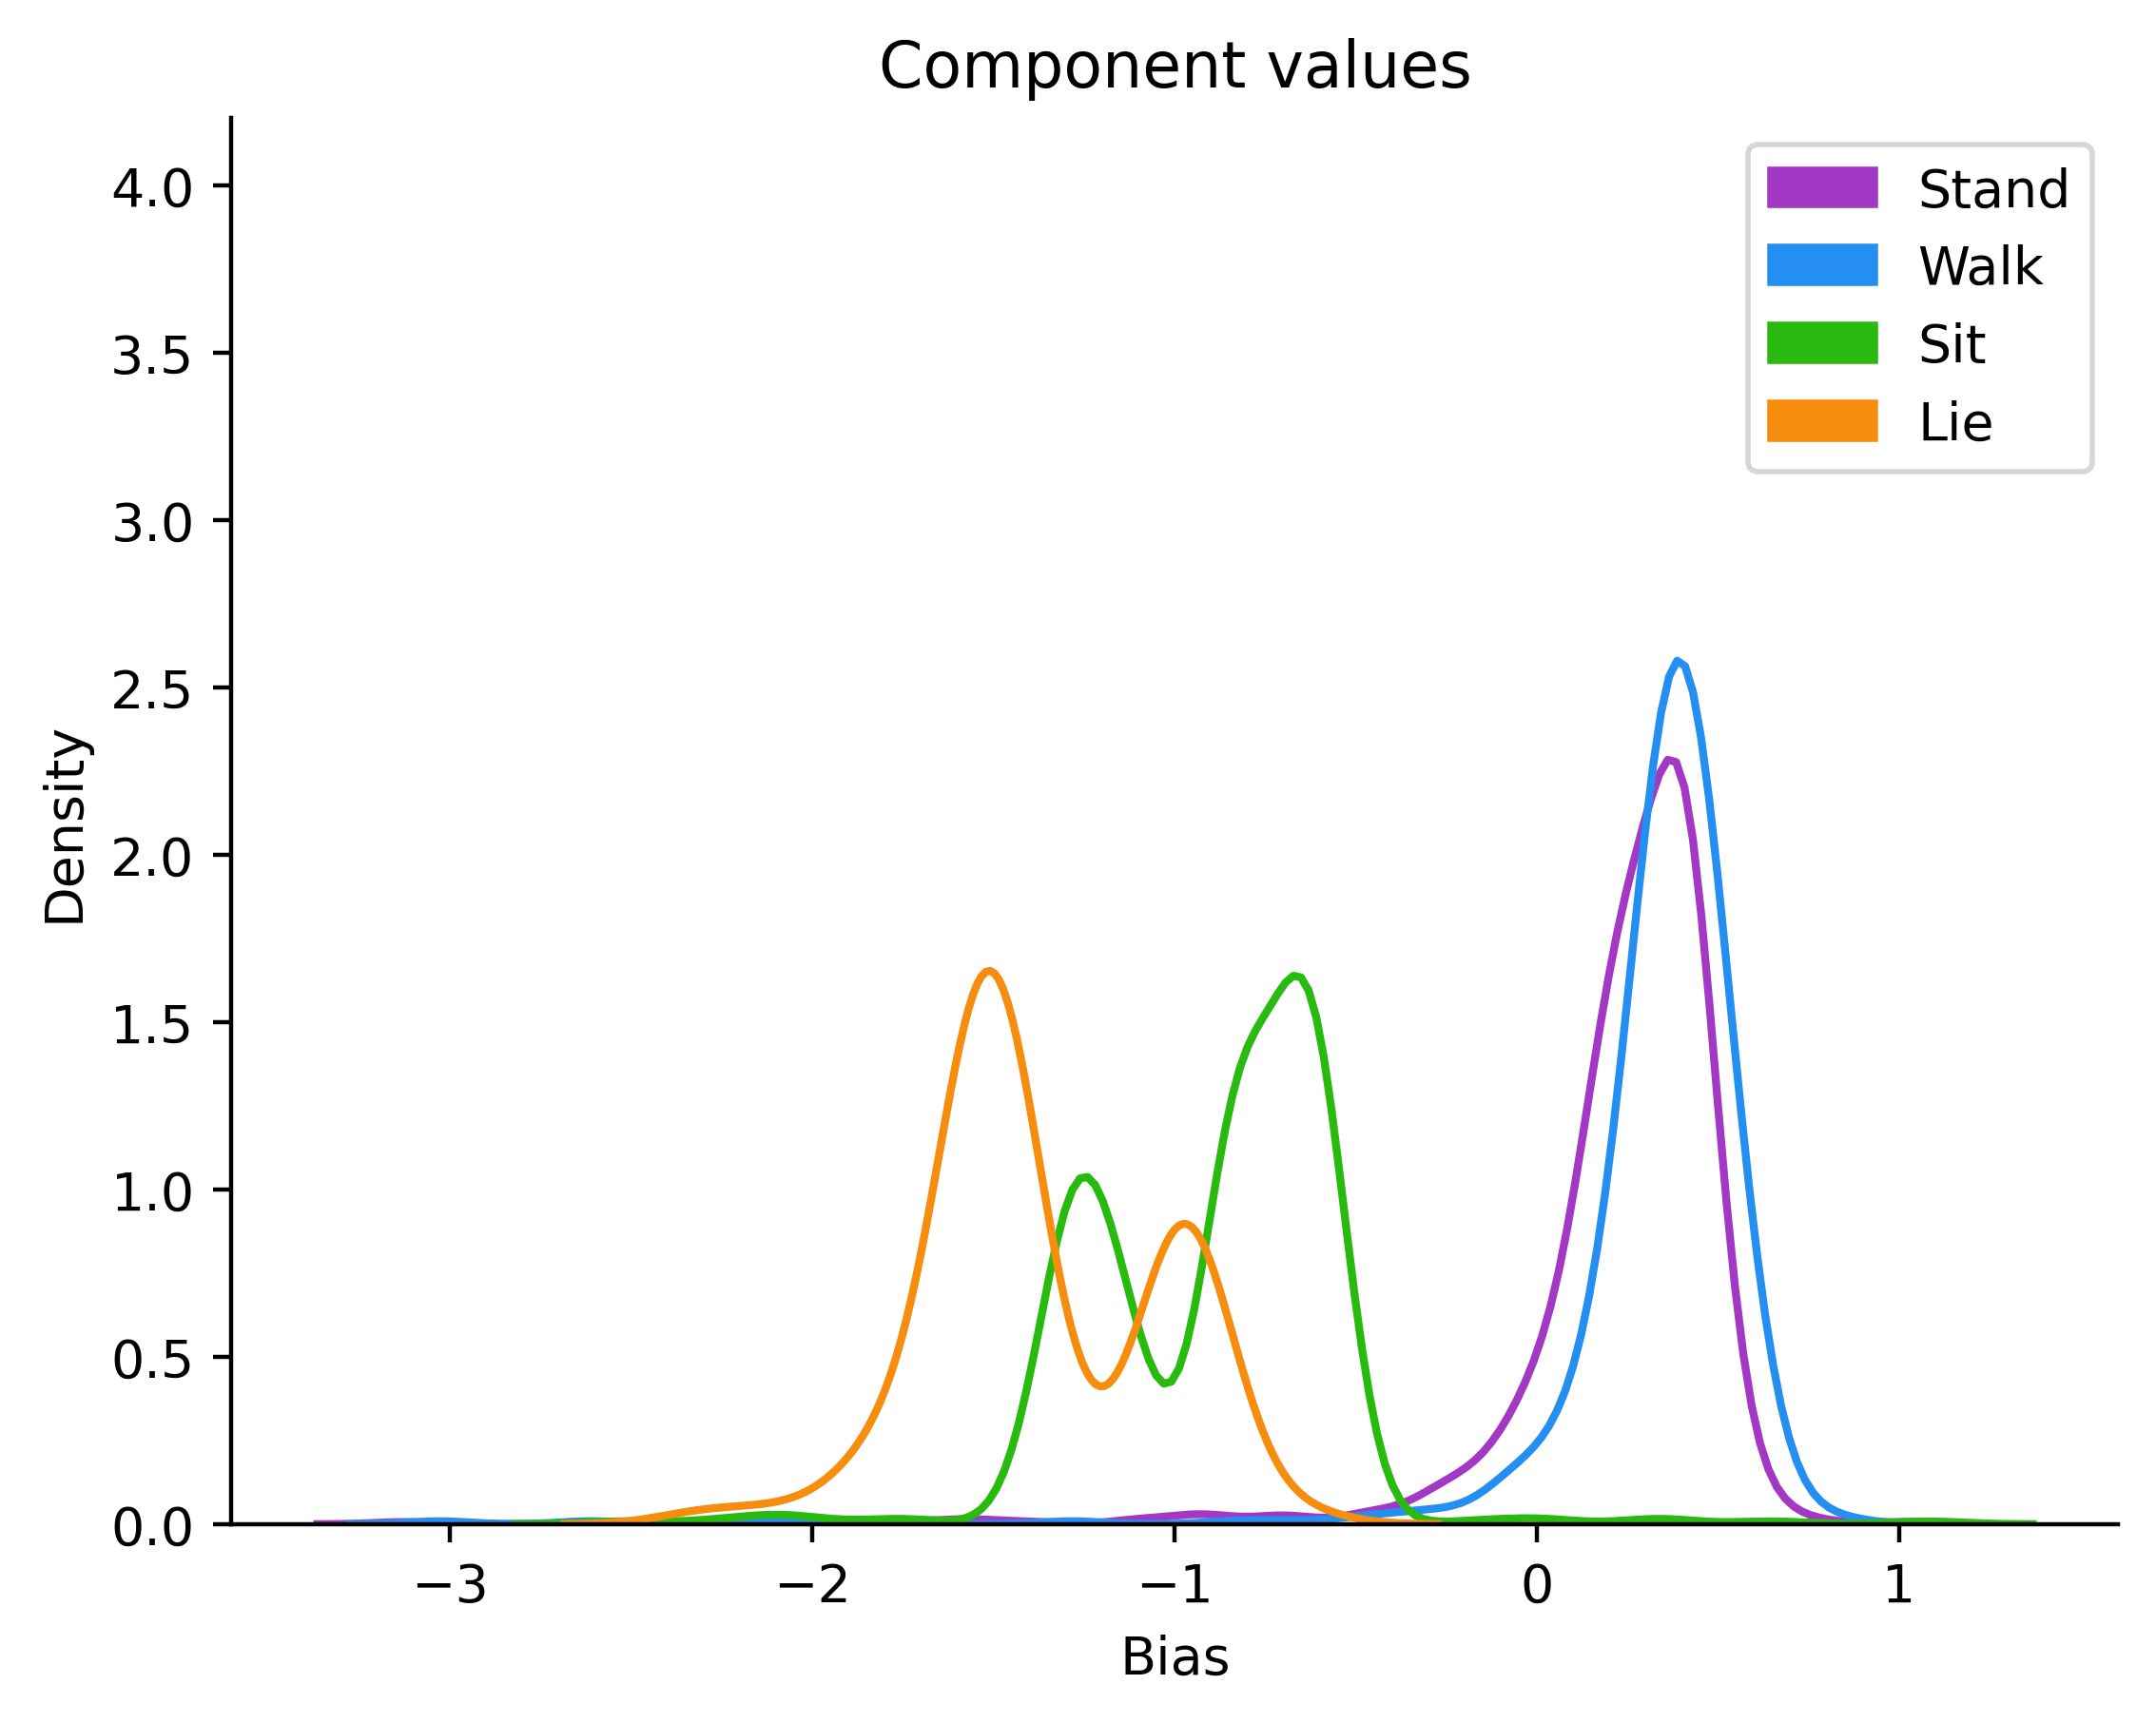

In [18]:
# Create density plot for bias component values per class
fig, ax = plt.subplots(dpi=400)

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

# Create density plot per class
patches = [None] * 4
for i in range(4):
    # Component 1 is scale following the defined decomposition
    sns.kdeplot(x_components[[y == i for y in test_gts], 0, 1], ax=ax, color=colors[i])
    patches[i] = mpatches.Patch(color=colors[i], label=class_dict[i])

# Figure annotations
plt.xlabel('Bias')
plt.ylabel('Density')
plt.ylim(0, 4.2)
plt.title('Component values')
plt.legend(handles=patches);

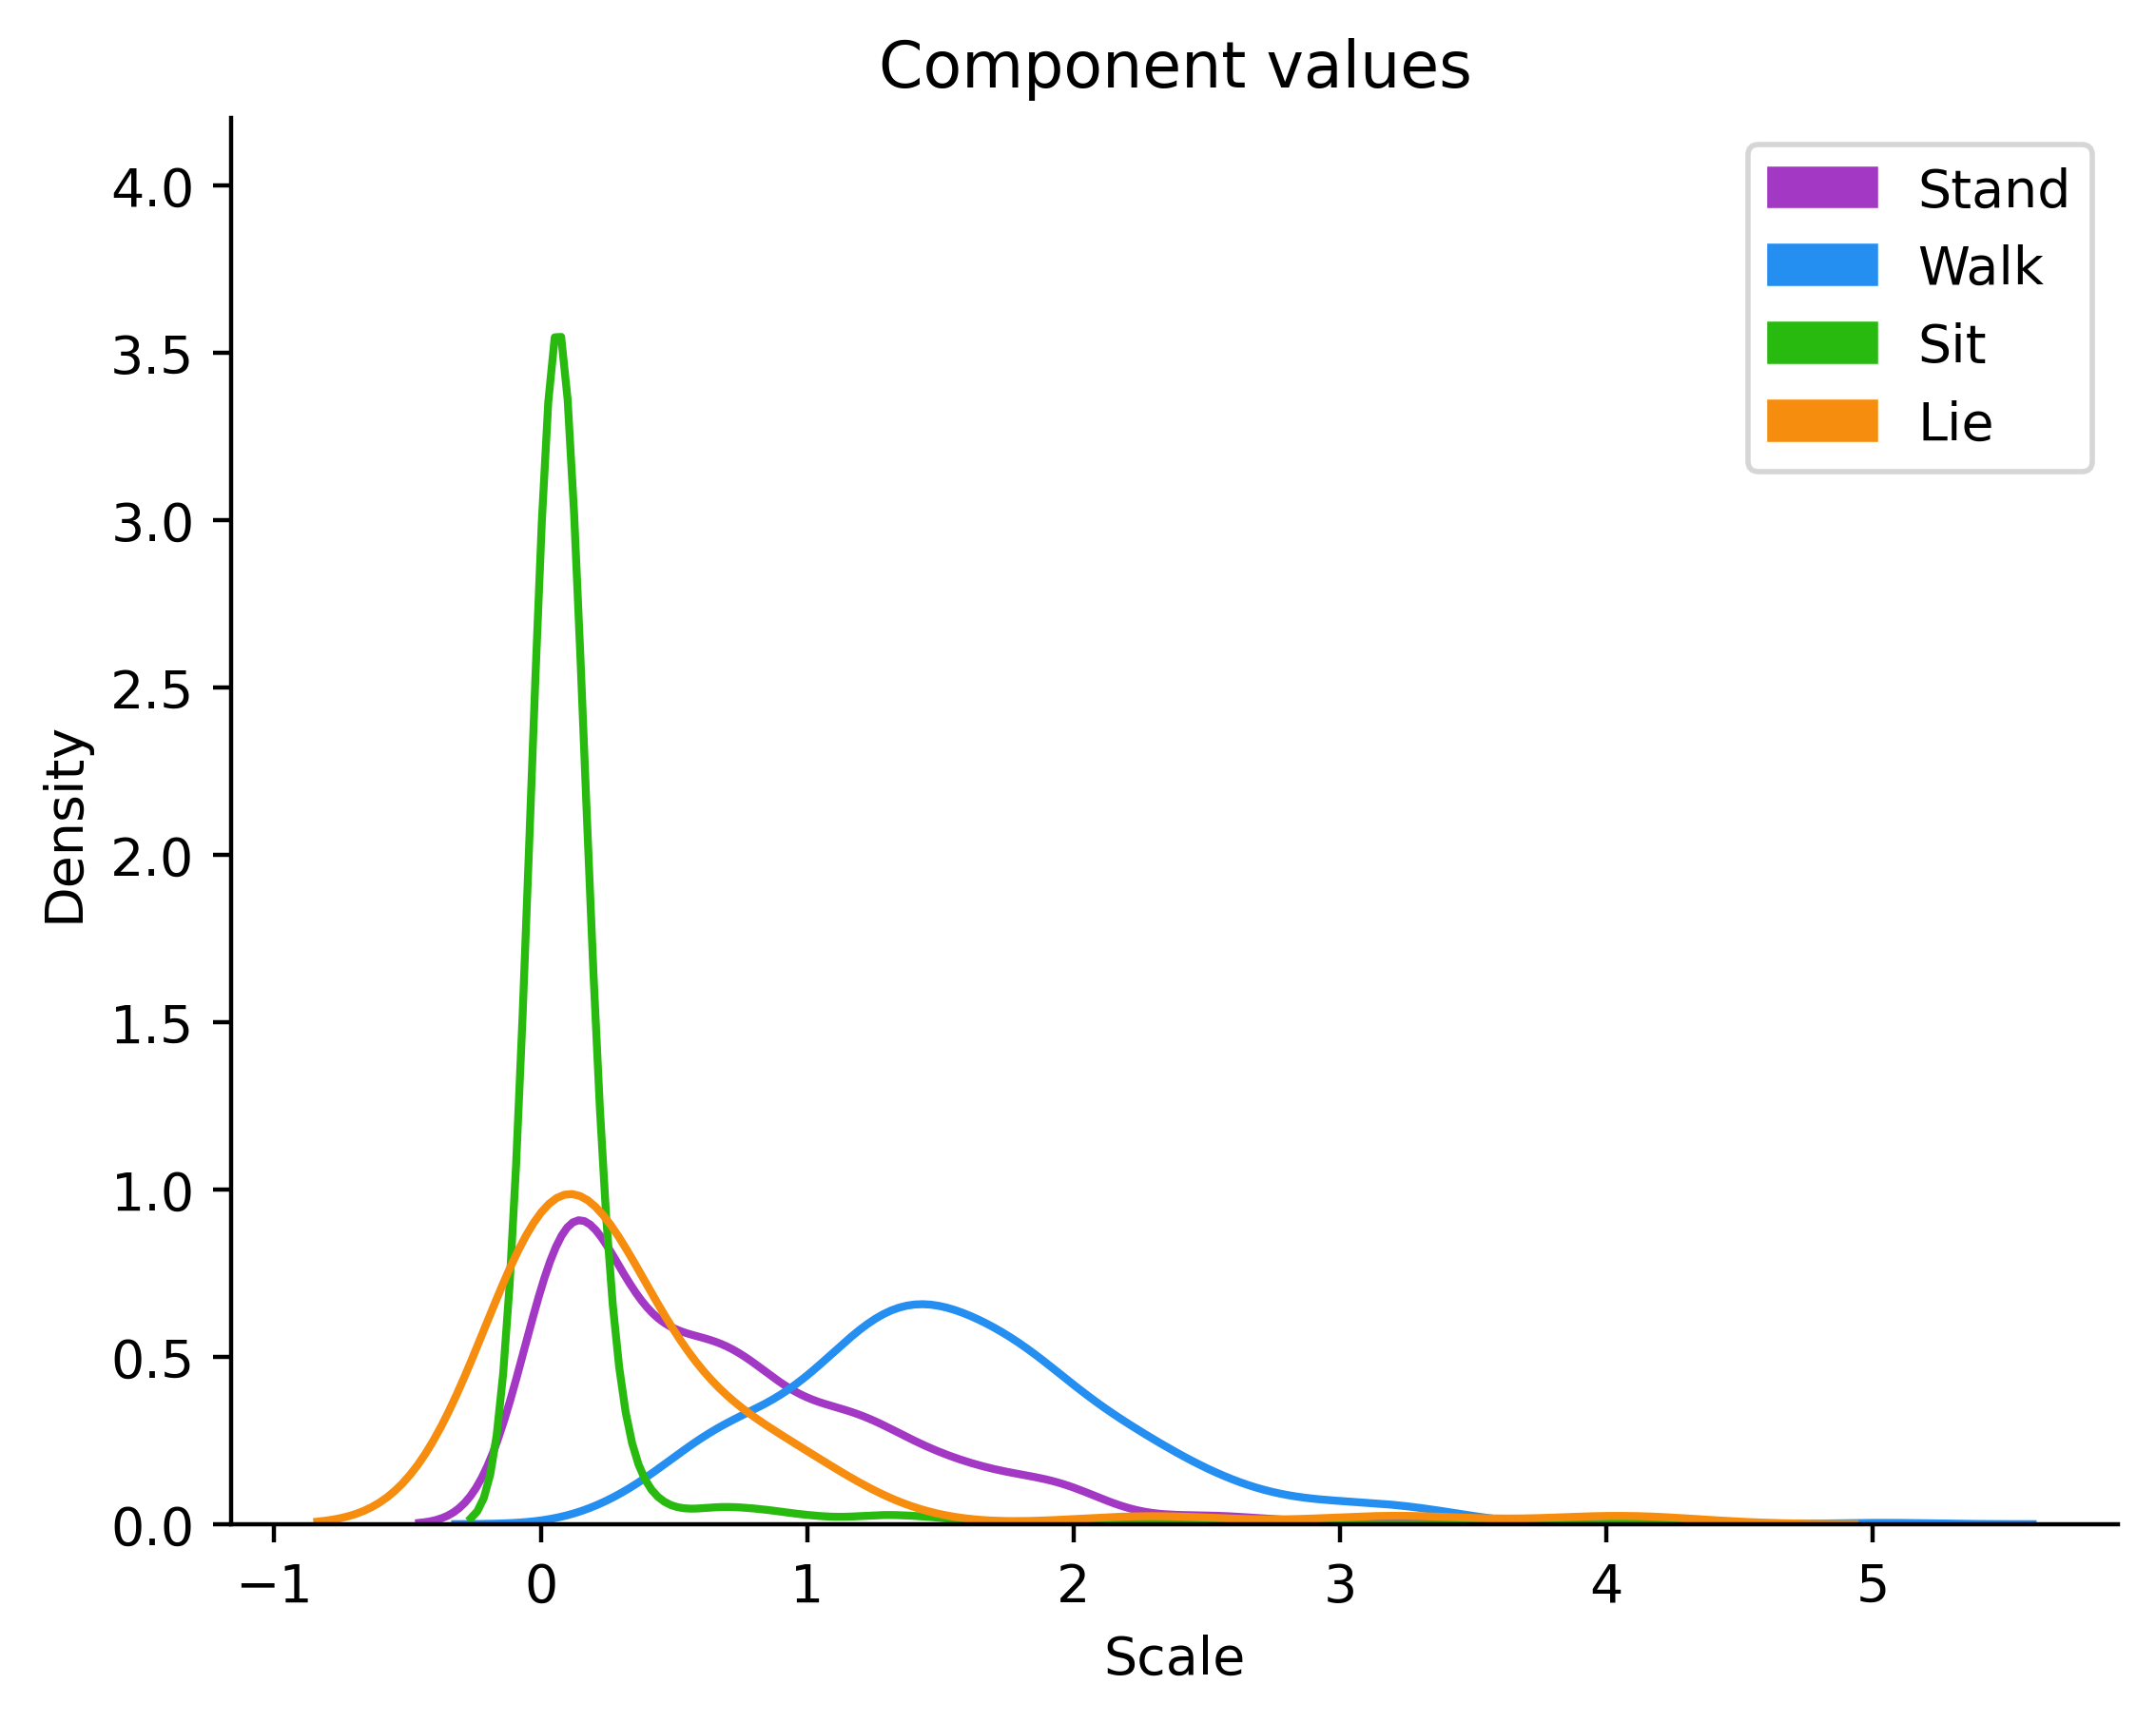

In [19]:
# Create density plot for bias component values per class
fig, ax = plt.subplots(dpi=400)

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

# Create density plot per class
patches = [None] * 4
for i in range(4):
    # Component 2 is scale following the defined decomposition
    sns.kdeplot(x_components[[y == i for y in test_gts], 0, 2], ax=ax, color=colors[i])

    patches[i] = mpatches.Patch(color=colors[i], label=class_dict[i])

# Figure annotations
plt.xlabel('Scale')
plt.ylabel('Density')
plt.ylim(0, 4.2)
plt.title('Component values')
plt.legend(handles=patches);

<h2>Global C-SHAP explanation</h2>

In [20]:
# Names to use for the components
components = ['Trend', 'Bias', 'Scale', 'Low frequency', 'Variance', 'High frequency']

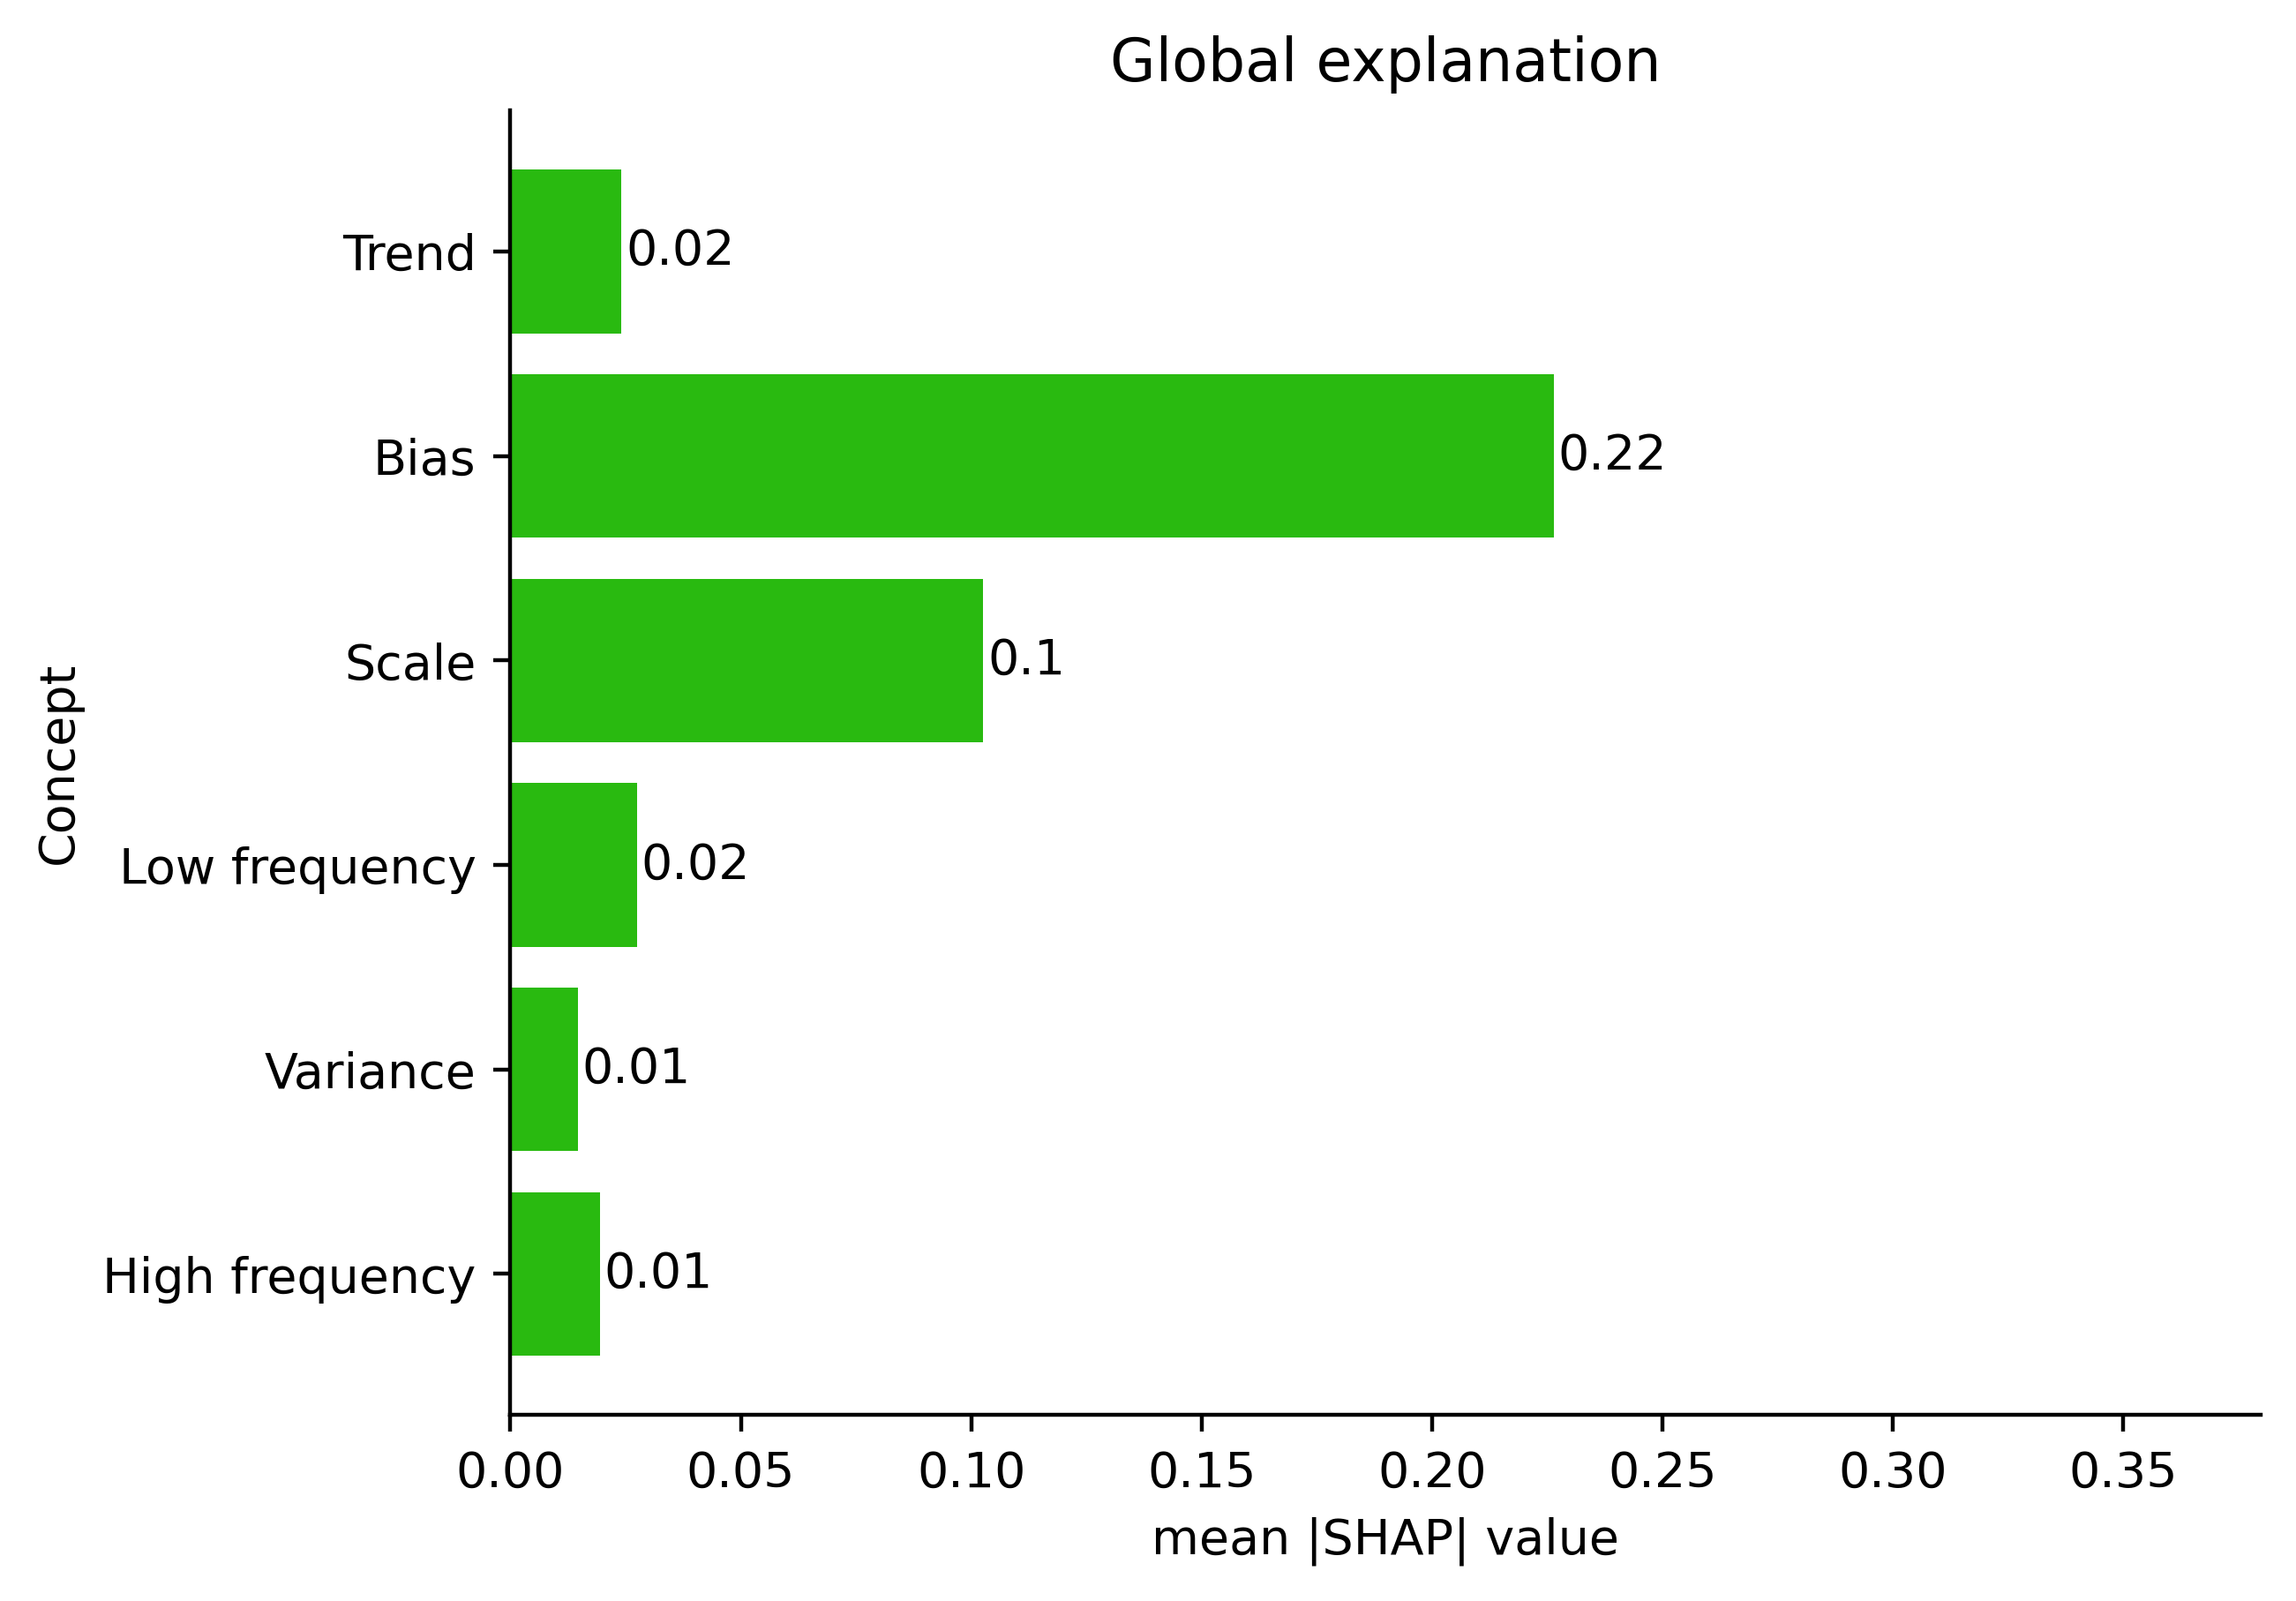

In [21]:
# Plot C-SHAP values
fig, ax = plt.subplots(dpi=400) # Initialize figure

y_pos = np.arange(len(components))  # Placeholder for y-axis
vals = np.mean(np.abs(shap_values), axis=0)  # Use mean of absolute SHAP values over the samples
vals = np.mean(vals, axis=-1)                               # Reapply mean for aggregation over classes

ax.barh(y_pos, vals, align='center', capsize=2, color=colors[2])    # Plot mean SHAP values as a horizontal barplot
ax.set_yticks(y_pos, labels=components)                             # Set component names as yticks

for i, v in enumerate(vals):                                        # Add SHAP values as text
    ax.text(v + 0.001, i, str(int(v * 100)/100),  verticalalignment='center')

plt.xlim(0, 0.38)                                           # Manually set x limits figures
ax.invert_yaxis()  # Start with first component instead of last

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

# Annotate figure
ax.set_xlabel('Performance')
ax.set_title('Global explanation')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
plt.xlabel('mean |SHAP| value')
plt.ylabel('Concept');

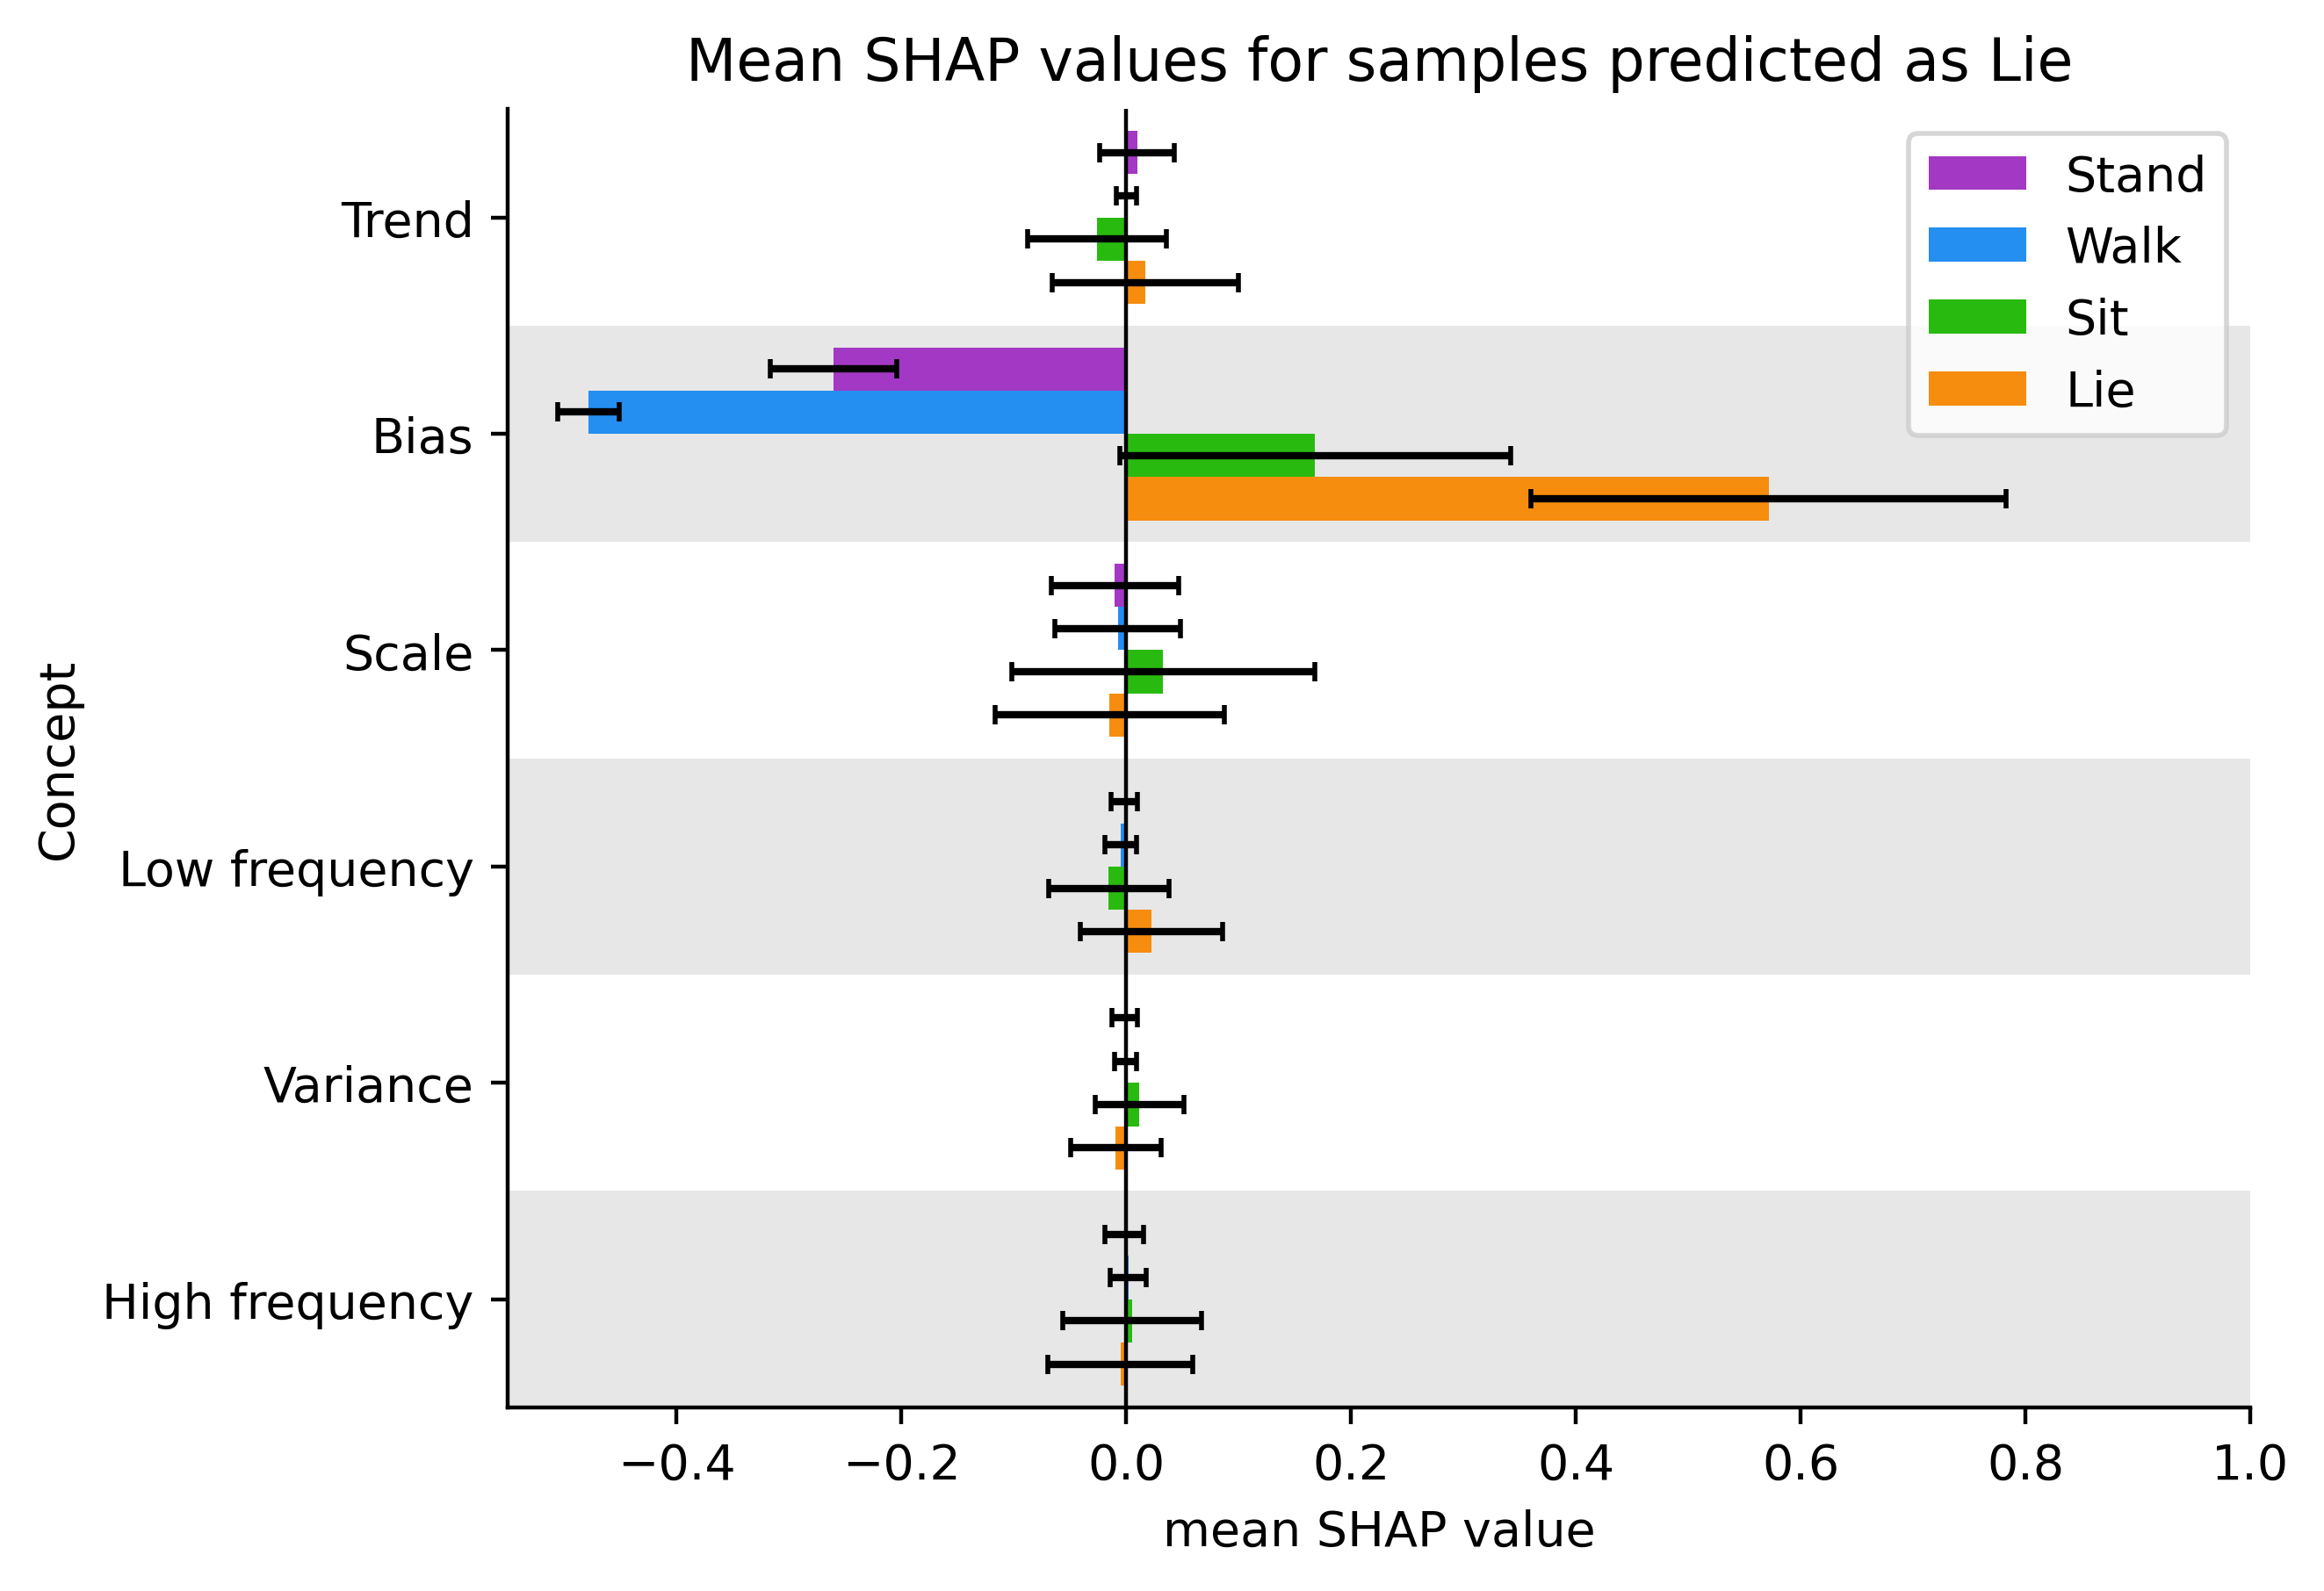

In [22]:
# Plot C-SHAP values with respect to given class
class_select = 3

# Initialize figure
plt.figure(dpi=400)
ax = plt.subplot()

# Add line at x = 0
plt.vlines(0, -1, shap_values.shape[1] - 0.5, color='#000000', linewidth=0.8)

# Add gray bars for readability
for i in range(len(decomposition.component_names)):
    if i % 2 == 0:
        plt.axhspan(i - 0.5, i + .5, facecolor='#D0D0D0', alpha=0.5)

# Select SHAP values for only the selected class
shap_select = shap_values[np.array(test_gts) == class_select]
for i in range(4):      # Iterate through the class output probabilities
    mean_values = list(reversed(np.mean(shap_select[:, :, i], axis=0)))   # Calculate mean over samples
    std_values = list(reversed(np.std(shap_select[:, :, i], axis=0)))     # Calculate std over samples

    y_pos = np.arange(len(components)) -0.3 + 0.2 * (3 - i)                     # Set vertical location of bar plot
    ax.barh(y_pos, mean_values, height=0.2, xerr=std_values, capsize=2, color=colors[i], label=class_dict[i]) # Bar plot

plt.yticks(np.arange(len(mean_values)), reversed(components));      # Create list of 0, ..., number of components for plotting
plt.xlim(-0.55, 1)                                                  # Manually set horiziontal limits
plt.ylim(0 - 0.5, len(mean_values) - 0.5)                           # Set vertical limits based on number of components
plt.legend()                                                        # Plot legend

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

# Annotate figures
plt.xlabel('mean SHAP value')
plt.ylabel('Concept')
plt.title('Mean SHAP values for samples predicted as ' + list(class_dict.values())[class_select]);